# Лабораторная 2. Кластеризация методом k-средних (k-means)
Выполнил: Двиков Даниил Владиславович

Активируем библиотеки

In [17]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import KMeans

import os

Задаем рабочую папку

In [18]:
os.chdir("E:/анализ данных/1 lab")


In [19]:
df = pd.read_csv("Леденцы.dat", sep=";")

In [20]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [21]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Во всех столбцах по 338 значений, значит, пропусков нет. Оценки везде лежат от 2 до 5, медиана у всех высказываний 3, то есть типичный ответ нейтральный.

Средние оценки близки, от 3,2 до 3,6. Чаще соглашаются с лечебными высказываниями (V9–V11) и про свежесть (V1–V3): у них 75-й процентиль равен 5, то есть как минимум четверть людей полностью согласны. Сладкое и концентрацию (V5–V8) поддерживают реже: 75-й процентиль у них 3, значит, согласных меньше четверти.

Стандартные отклонения у всех переменных похожие (0,82–0,99)

In [22]:
print(df.dtypes)
print('Все значения в данных:', np.unique(df.values))

V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object
Все значения в данных: [2 3 4 5]


Видим, что используется порядковая шкала от 2 до 5. Все 11 переменных измерены в одной и той же шкале с одинаковым диапазоном, поэтому стандартизация данных не нужна.

По дендограмме видно, что распределение выделяет 4 кластера

## Каменистая осыпь
Применим модель для разного числа кластеров, чтобы построить график каменистой осыпи. Метод ```inertia_``` вернёт сумму квадратов расстояний от каждой точки данных до центра ближайшего к ней кластера. Кластеризацию будем считать условно хорошей, если инерция перестаёт сильно уменьшаться при увеличении числа кластеров.

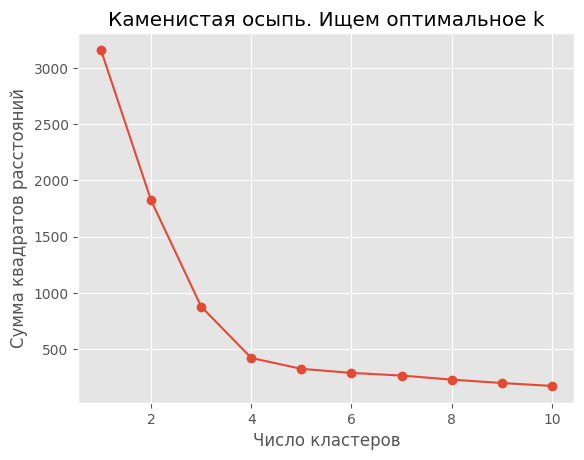

In [23]:
K = range(1, 11)

# Вычисляем значения критерия качества для разного числа кластеров
models = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(df) for k in K]
dist = [model.inertia_ for model in models]

# Строим график каменистая осыпь
plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

Сумма квадратов резко падает до k = 4, а дальше почти не меняется. 

Вывод: число кластеров равно 4.

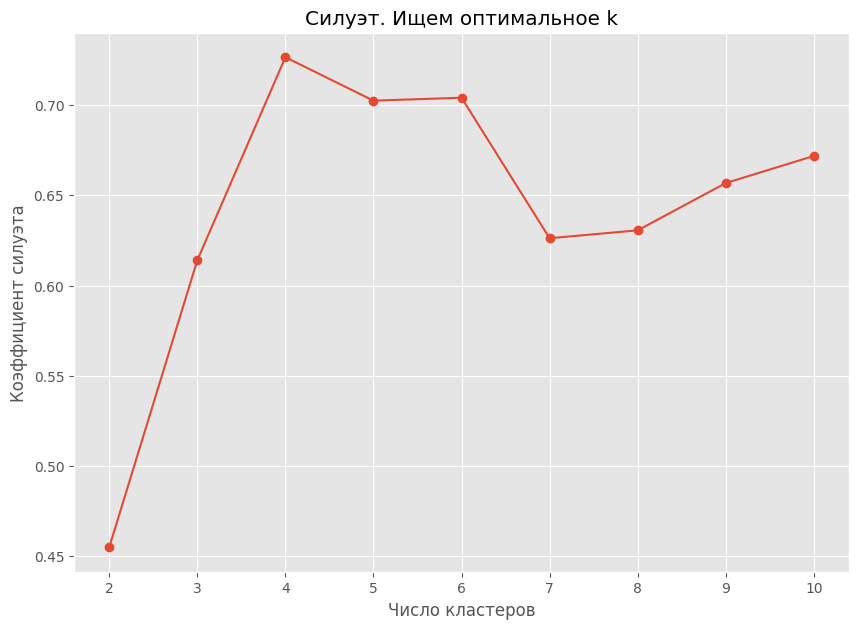

In [24]:
from sklearn.metrics import silhouette_score

K = range(2, 11)

# Вычисляем коэффициент силуэта для разного числа кластеров
models = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(df) for k in K]
sil = [silhouette_score(df, model.labels_) for model in models]

plt.figure(figsize=(10, 7))
plt.plot(K, sil, marker='o')
plt.xticks(K)
plt.xlabel('Число кластеров')
plt.ylabel('Коэффициент силуэта')
plt.title('Силуэт. Ищем оптимальное k')
plt.show()

Самый высокий силуэт получился при 4 кластерах, примерно 0,73. Дальше он только падает, так что и по этому графику определили, что число кластеров равно 4

## Кластеризация методом kmeans

In [25]:
model = KMeans(n_clusters=4, random_state=42, max_iter=300, n_init=10, verbose=0)
model.fit(df)
df['cluster'] = model.labels_
df.groupby('cluster').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
1,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000


In [26]:
print('Число итераций до сходимости:', model.n_iter_)

Число итераций до сходимости: 2


K-means разбил респондентов на 4 кластера, и у каждого одна главная причина есть леденцы. Кластер 0 высоко оценил V9-V11, это те, кто ест леденцы от простуды. Кластер 1 - сладкоежки (V5-V6). Кластер 2 - те, кому важно свежее дыхание (V1-V4). Кластер 3 ест леденцы, чтобы сосредоточиться (V7-V8). Остальные высказывания в каждом кластере оценены примерно на 3. Алгоритм сошёлся всего за 2 итерации, значит, группы в данных выражены очень чётко.

Выведем центры кластеров

In [27]:
centers = pd.DataFrame(model.cluster_centers_, columns=df.columns[:11])
centers.round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
1,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00


In [28]:
labels = model.labels_

# Расстояния объектов до своих центроидов
distances = np.linalg.norm(
    df.iloc[:, :11].to_numpy() - centers.to_numpy()[labels],
    axis=1
)

# Среднее расстояние для каждого кластера
pd.DataFrame({
    'Кластер': labels,
    'Расстояние': distances
}).groupby('Кластер').mean().round(2)

,Расстояние
Кластер,
0,1.39
1,0.83
2,0.85
3,0.37


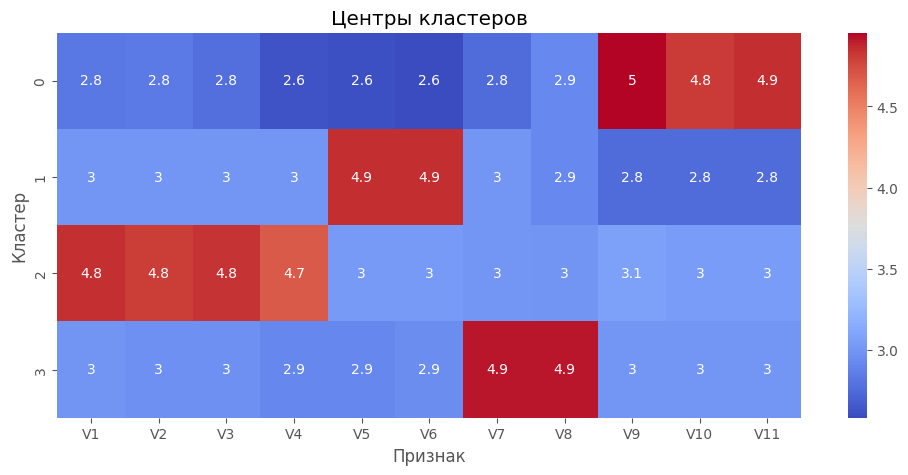

In [29]:
# Тепловая карта центров кластеров
plt.figure(figsize=(12, 5))
sns.heatmap(centers, annot=True,  cmap='coolwarm')
plt.title('Центры кластеров')
plt.xlabel('Признак')
plt.ylabel('Кластер')
plt.show()

Среднее расстояние от объектов до центра своего кластера небольшое: от 0,37 до 1,39. Расстояния между самими центроидами намного больше, от 3,90 до 5,19. Значит, внутри кластеров объекты собраны плотно, а сами кластеры далеко друг от друга.

Ближе всего центры кластеров 1 и 3: сладкоежки и концентрация. Дальше всего кластеры 0 и 2: лечебный и свежее дыхание.

Это объясняется блоками высказываний, по которым различаются кластеры. Сладкоежки и концентрация расходятся только в двух парах высказываний (V5-V6 и V7-V8), а по остальным семи оба кластера отвечают нейтрально, около 3. Лечебный кластер и кластер свежего дыхания расходятся сразу в семи высказываниях (V1-V4 и V9-V11). К тому же лечебный кластер оценивает свежесть даже ниже нейтрального, поэтому расстояние между ними самое большое.

In [30]:
sizes = df.groupby('cluster').size()
pd.DataFrame({'Человек': sizes,
              'Доля, %': (sizes / len(df) * 100).round(1)})

,Человек,"Доля, %"
cluster,,
0,108,32.0
1,61,18.0
2,110,32.5
3,59,17.5


In [31]:
means = df.groupby('cluster').mean().round(2)
means

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
1,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00


Средняя оценка по каждому блоку высказываний

In [32]:
blocks = {'Освежение (V1–V4)':    ['V1', 'V2', 'V3', 'V4'],
          'Сладкое (V5–V6)':      ['V5', 'V6'],
          'Концентрация (V7–V8)': ['V7', 'V8'],
          'Лечение (V9–V11)':     ['V9', 'V10', 'V11']}

pd.DataFrame({name: means[cols].mean(axis=1) for name, cols in blocks.items()}).round(2)

,Освежение (V1–V4),Сладкое (V5–V6),Концентрация (V7–V8),Лечение (V9–V11)
cluster,,,,
0,2.76,2.60,2.84,4.87
1,3.00,4.85,2.96,2.75
2,4.79,3.04,3.00,3.06
3,2.97,2.94,4.92,3.00


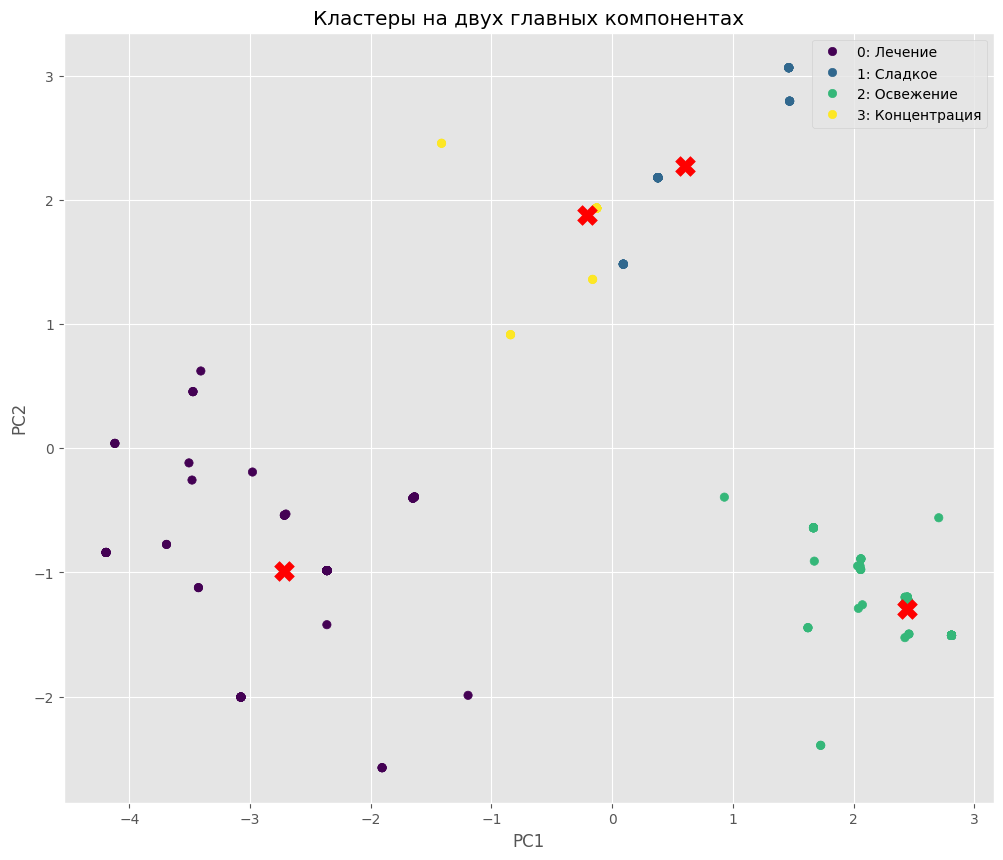

In [33]:
from sklearn.decomposition import PCA

names = ['0: Лечение', '1: Сладкое', '2: Освежение', '3: Концентрация']

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df.iloc[:, :11])
centers_pca = pca.transform(centers)
plt.figure(figsize=(12, 10))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=model.labels_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200)
plt.legend(sc.legend_elements()[0], names)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Кластеры на двух главных компонентах')
plt.show()

На плоскости двух главных компонент лечебный кластер (0, слева) и кластер свежего дыхания (2, справа внизу) находятся далеко друг от друга и от остальных. Сладкоежки (1) и концентрация (3) расположены сверху рядом, их центры почти соседние: в проекции на две компоненты эти группы видны хуже, потому что отличаются в основном по V5–V8. У кластера 3 видно мало точек: большинство его респондентов ответили одинаково и лежат в одной точке под крестиком центра.

## Выводы:
Первый кластер (108 человек) едят леденцы, когда болеют. Они высоко оценили V9–V11: боль в горле, заложенный нос, плохое самочувствие. Остальные причины у них оценены даже ниже тройки, так что для них леденец скорее лекарство, чем сладость.

Во второй кластер (110 человек) попали те, кому важно свежее дыхание. У них высокие оценки по V1–V4: освежить дыхание и рот, убрать неприятный вкус, чувствовать себя увереннее при общении. Другие высказывания они оценили нейтрально.

Третий кластер (59 человек) едят леденцы, чтобы сосредоточиться или отвлечься на пару минут и подумать (V7 и V8 по 4,92). Скорее всего, это люди, которые много работают или учатся.

Четвёртый кластер (61 человек) – сладкоежки. Для них леденец просто заменяет конфеты, когда хочется чего-нибудь сладкого (V5 и V6 по 4,85). Лечебный эффект их почти не интересует (2,75).

В итоге получилось четыре понятных сегмента. Даже самый маленький из них составляет 17,5 % выборки, так что все группы достаточно крупные. Самые большие сегменты связаны с простудой и свежим дыханием, вместе это около двух третей респондентов, поэтому компании в первую очередь стоит ориентироваться на них.